In [3]:
# %% [markdown]
# # Setup and Configuration

# %%
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from skimage.restoration import unwrap_phase

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

# Import project modules
import src.phase_extraction as pe
import src.calibration as calib
import src.slit_analysis as sa

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# %% [markdown]
# # Physical Constants and Parameters

# %%
# Nozzle & Physical Constants
NOZZLE_WIDTH_MM = 6.0
NOZZLE_OPENING_MM = 0.5
TARGET_GAS = "argon"
THEORETICAL_PEAK_DENSITY_30BAR = 4.33e19  # cm^-3

# Processing Parameters
DATA_BASE_PATH = r"C:\Users\vmlab\Documents\data\files\2026\03\25"
ROI_BOUNDS = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
MAX_HEIGHT_MM = 6.0

In [65]:
# %% [markdown]
# # Plotting Helper

# %%
import matplotlib.ticker as ticker

def plot_density_results(density_map, x_mm, y_mm, exit_lineout, px_to_mm, pressure, theo_density, measured_mean):
    """Generates a side-by-side plot of the 2D Density Map and the 1D Nozzle Exit Lineout."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor="white")

    # --- Plot 1: 2D Density Map ---
    ax1 = axes[0]
    ax1.set_facecolor("white")

    # Reverting to 98th percentile for much better visual contrast!
    m = np.nanpercentile(np.abs(density_map), 98.0)
    extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

    im = ax1.imshow(density_map, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)
    # ax1.set_title(f"Density Map {pressure} bar", color="black", fontsize=18, fontweight="bold", pad=12)
    ax1.set_xlabel("x [mm]", color="black", fontsize=14)
    ax1.set_ylabel("Height above nozzle [mm]", color="black", fontsize=14)
    ax1.tick_params(colors="black", labelsize=12)
    for spine in ax1.spines.values(): spine.set_color("black")

    cbar = fig.colorbar(im, ax=ax1)
    cbar.set_label("Density [cm$^{-3}$]", color="black", fontsize=14)

    # Force scientific notation cleanly on the 2D colorbar
    formatter = ticker.ScalarFormatter(useMathText=False)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0, 0))
    cbar.ax.yaxis.set_major_formatter(formatter)

    cbar.ax.yaxis.set_tick_params(color="black", labelsize=12)
    plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')
    cbar.ax.yaxis.get_offset_text().set_fontsize(11)
    cbar.ax.yaxis.get_offset_text().set_color('black')

    # --- Plot 2: 1D Lineout at Exit ---
    ax2 = axes[1]
    ax2.set_facecolor("white")
    x_axis_mm = np.arange(len(exit_lineout)) * px_to_mm

    ax2.plot(x_axis_mm, exit_lineout, label="Measured Density", color="blue", linewidth=2.5)

    # Highlight the 1mm - 3.5mm averaging region
    # ax2.axvspan(1.0, 3.5, color="gray", alpha=0.2, label="Averaging Region (1.0-3.5mm)")

    ax2.axhline(y=theo_density, color="red", linestyle="--", linewidth=2.5,
                label=f"1D De Laval ({theo_density:.1e} cm$^{{-3}}$)")
    ax2.axhline(y=measured_mean, color="green", linestyle=":", linewidth=3,
                label=f"Measured Mean ({measured_mean:.1e} cm$^{{-3}}$)")

    # ax2.set_title(f"Density Profile at Nozzle Exit", color="black", fontsize=18, fontweight="bold", pad=12)
    ax2.set_xlabel("Position Across Slit [mm]", color="black", fontsize=14)
    ax2.set_ylabel("Gas Density [cm$^{-3}$]", color="black", fontsize=14)
    ax2.tick_params(colors="black", labelsize=12)
    for spine in ax2.spines.values(): spine.set_color("black")
    ax2.grid(True, linestyle=":", alpha=0.7, color="gray")

    legend = ax2.legend(loc="lower right", fontsize=12, facecolor="white", framealpha=1.0, edgecolor="black")
    for text in legend.get_texts(): text.set_color("black")

    plt.tight_layout()
    plt.show()

In [70]:
# %% [markdown]
# # 1. Compute 2D Density Maps (Heavy Calculation)

# %%
def compute_2d_density_map(pressure_bar, base_path, roi):
    """
    Extracts phase, calculates depth, and returns the full 2D density map data.
    Does NOT plot or extract 1D lineouts.
    """
    path_perp = f"{base_path}\\Ar-{pressure_bar}bar"
    path_para = f"{base_path}\\Ar-{pressure_bar}bar 90deg"

    # --- 1. Phase Extraction at 0 degrees (Perpendicular) ---
    ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(path_perp, roi=roi)
    ref_fourier = pe.get_fourier(ref_roi)
    exp_fourier = pe.get_fourier(exp_roi)
    dom_freq = pe.get_dominant_frequency(ref_fourier, debug=False)
    delta_phase_wrap = pe.get_delta_phase_wrapped(ref_fourier, exp_fourier, dom_freq, debug=False)
    ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
    x_left, x_right = calib.detect_nozzle_x_range(ref_roi, ref_edge)
    calib_phase_perp, _ = calib.calibrate_phase(delta_phase_wrap, ref_edge, x_left, x_right, debug=False)
    calib_phase_perp = unwrap_phase(calib_phase_perp)
    px_to_mm = calib.calculate_px_to_mm(x_left, x_right, NOZZLE_WIDTH_MM)

    # --- 2. Phase Extraction at 90 degrees (Parallel) ---
    ref_img_para, exp_img_para, ref_roi_para, exp_roi_para = pe.get_interferometry_images(path_para, roi=roi)
    ref_fourier_para = pe.get_fourier(ref_roi_para)
    exp_fourier_para = pe.get_fourier(exp_roi_para)
    dom_freq_para = pe.get_dominant_frequency(ref_fourier_para, debug=False)
    delta_phase_wrap_para = pe.get_delta_phase_wrapped(ref_fourier_para, exp_fourier_para, dom_freq_para, debug=False)
    ref_edge_para, *_ = calib.estimate_nozzle_edge(ref_roi_para)
    x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi_para, ref_edge_para)
    calib_phase_para, _ = calib.calibrate_phase(delta_phase_wrap_para, ref_edge_para, x_left_para, x_right_para, debug=False)

    # --- 3. Slit Analysis & Density Mapping ---
    phi_cropped_para = sa.crop_and_format_phase_map(
        calib_phase_para, nozzle_edge_y=ref_edge_para, px_to_mm=px_to_mm, max_height_mm=MAX_HEIGHT_MM
    )
    y_mm_para, depth_fit_para, _ = sa.estimate_depth_profile(
        phi_cropped_para, px_to_mm, nozzle_opening=NOZZLE_OPENING_MM,
        fit_type="log_constrained", exclude_y_mm=0.6, debug_show=False
    )
    phi_cropped_perp = sa.crop_and_format_phase_map(
        calib_phase_perp, nozzle_edge_y=ref_edge - 50, px_to_mm=px_to_mm, max_height_mm=MAX_HEIGHT_MM
    )
    density_map, x_mm, y_mm = sa.phase_to_density(
        phi_cropped_perp, px_to_mm, depth_y_mm=y_mm_para, depth_profile_mm=depth_fit_para, gas=TARGET_GAS
    )

    return {
        "density_map": density_map,
        "x_mm": x_mm,
        "y_mm": y_mm,
        "px_to_mm": px_to_mm,
        "x_left": x_left,
        "x_right": x_right
    }

pressures = np.array([5, 10, 15, 20, 25, 30])
results_2d = {}

for p in pressures:
    print(f"Calculating 2D phase and density maps for {p} bar...")
    results_2d[p] = compute_2d_density_map(pressure_bar=p, base_path=DATA_BASE_PATH, roi=ROI_BOUNDS)

print("\n✅ All 2D density maps calculated and stored in memory!")

Calculating 2D phase and density maps for 5 bar...
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Calculating 2D phase and density maps for 10 bar...
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Calculating 2D phase and density maps for 15 bar...
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Calculating 2D phase and density maps for 20 bar...
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Calculating 2D phase and density maps for 25 bar...
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Unsupported data type for _convert.
Calculating 2D phase 


Results for 5 bar
Measured Mean Density (x=1.0-3.5mm): 7.97e+18 cm^-3
Theoretical De Laval Prediction:   7.22e+18 cm^-3
Theoretical overestimation factor: ~0.9x


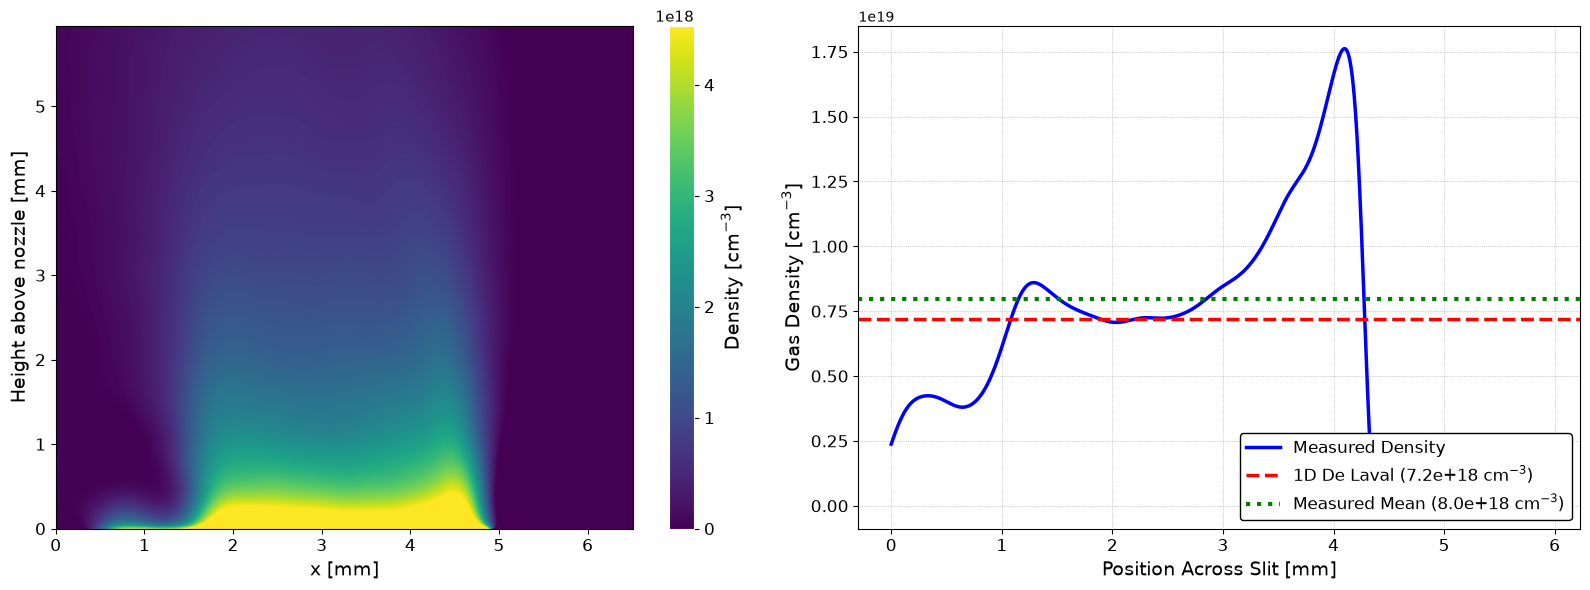


Results for 10 bar
Measured Mean Density (x=1.0-3.5mm): 1.50e+19 cm^-3
Theoretical De Laval Prediction:   1.44e+19 cm^-3
Theoretical overestimation factor: ~1.0x


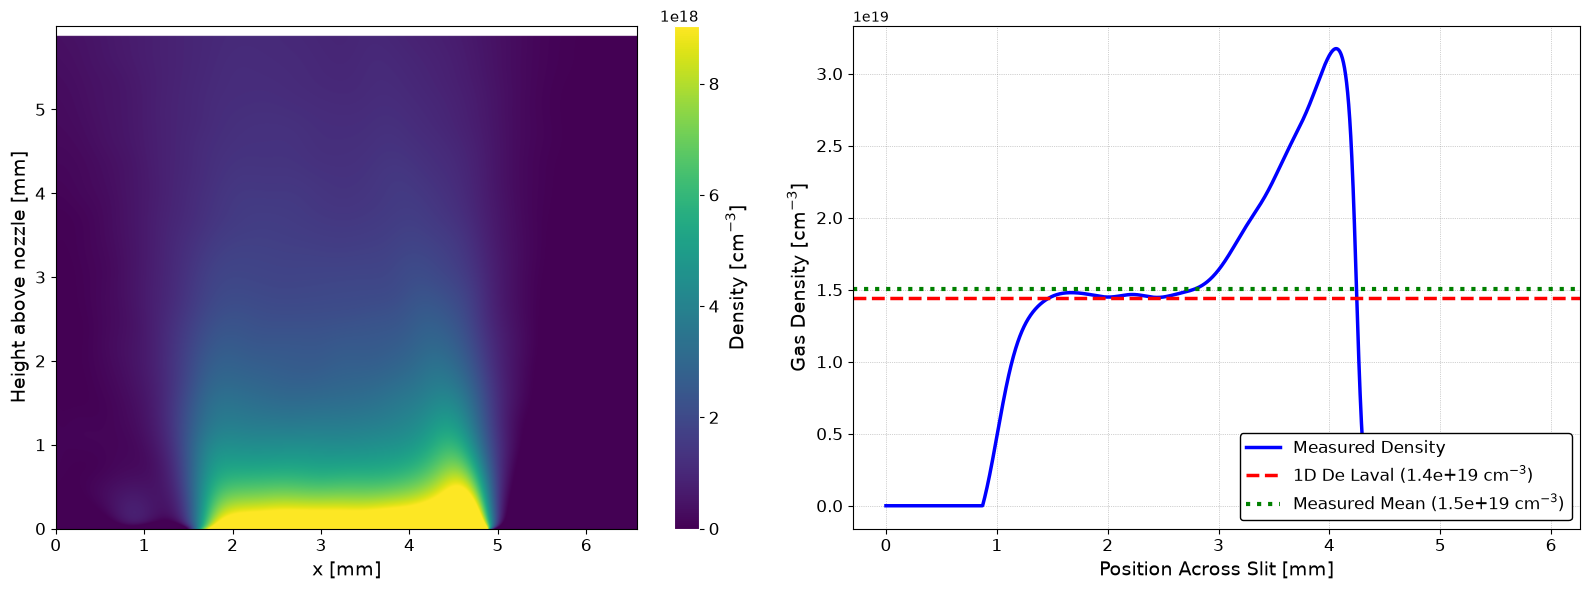


Results for 15 bar
Measured Mean Density (x=1.0-3.5mm): 1.35e+19 cm^-3
Theoretical De Laval Prediction:   2.16e+19 cm^-3
Theoretical overestimation factor: ~1.6x


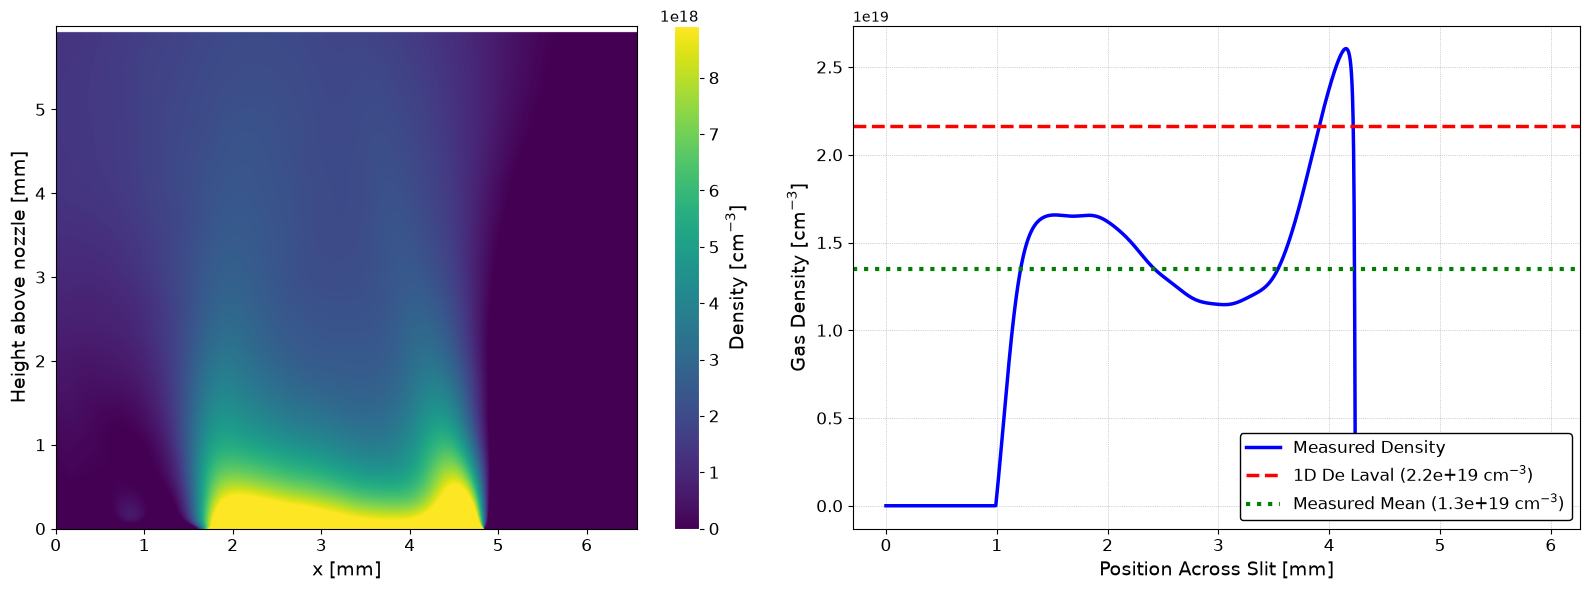


Results for 20 bar
Measured Mean Density (x=1.0-3.5mm): 3.03e+19 cm^-3
Theoretical De Laval Prediction:   2.89e+19 cm^-3
Theoretical overestimation factor: ~1.0x


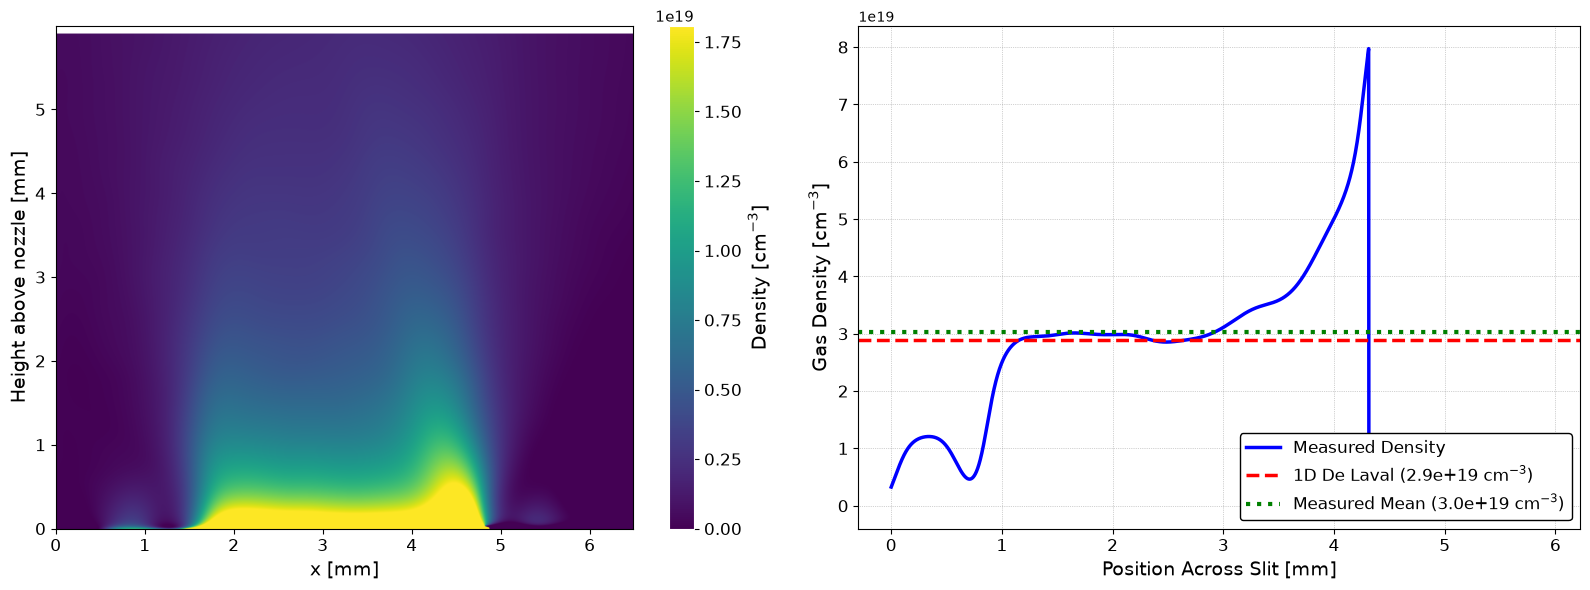


Results for 25 bar
Measured Mean Density (x=1.0-3.5mm): 2.57e+19 cm^-3
Theoretical De Laval Prediction:   3.61e+19 cm^-3
Theoretical overestimation factor: ~1.4x


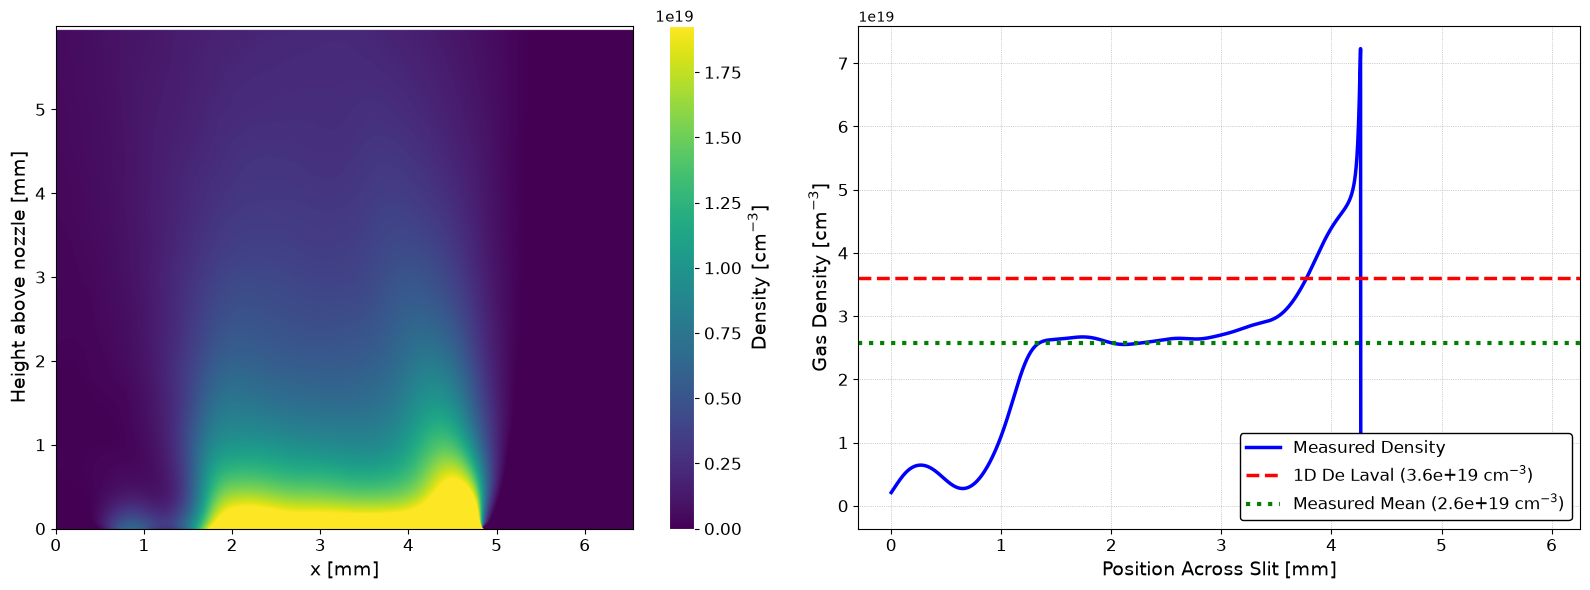


Results for 30 bar
Measured Mean Density (x=1.0-3.5mm): 3.36e+19 cm^-3
Theoretical De Laval Prediction:   4.33e+19 cm^-3
Theoretical overestimation factor: ~1.3x


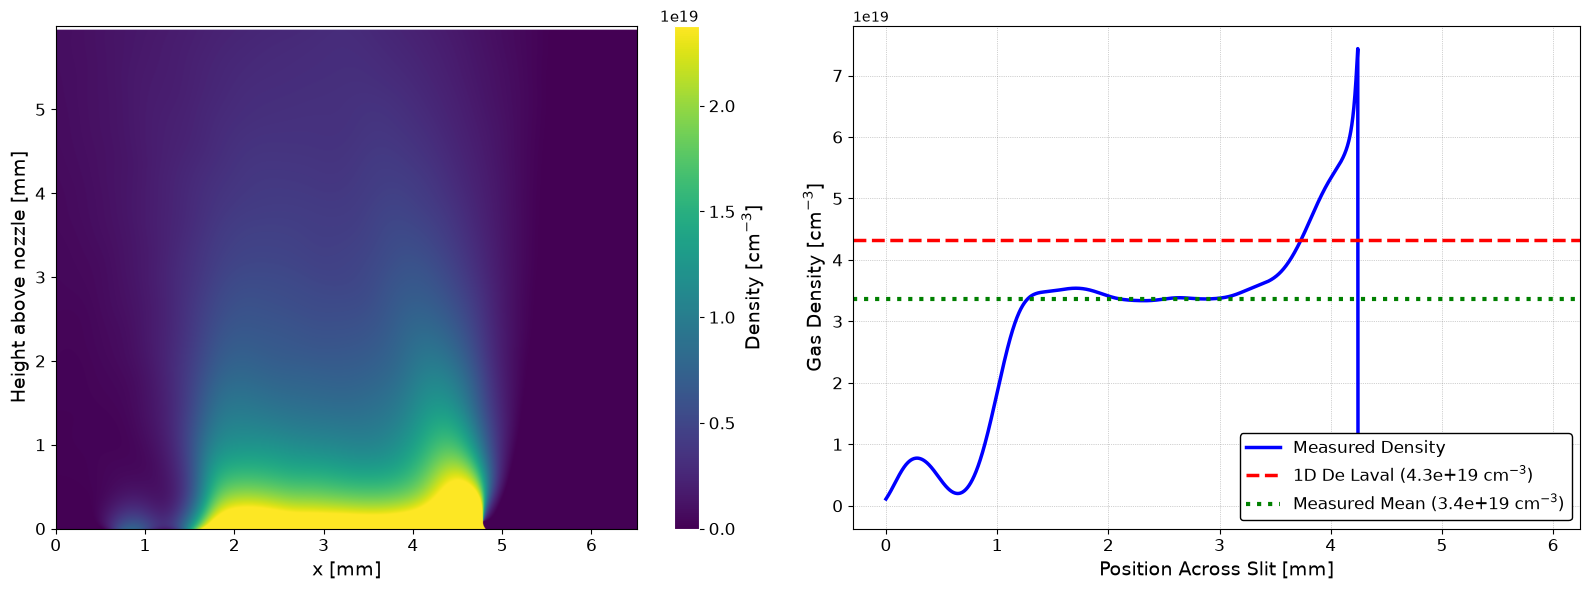

In [71]:
# %% [markdown]
# # 2. Extract 1D Profiles and Plot Results (Fast Execution)

# %%
measured_means = []
theoretical_densities = []

for p in pressures:
    # 1. Retrieve the pre-calculated 2D arrays
    data = results_2d[p]
    density_map = data["density_map"]
    px_to_mm = data["px_to_mm"]
    x_left = data["x_left"]
    x_right = data["x_right"]
    x_mm = data["x_mm"]
    y_mm = data["y_mm"]

    # 2. Extract Lineout right at the Nozzle Exit (y=0)
    edge_z_pixel = 0
    exit_lineout = density_map[edge_z_pixel, int(x_left):int(x_right)]

    # 3. Calculate Segment Mean (x = 1.0mm to 3.5mm)
    start_px = int(1.0 / px_to_mm)
    end_px = int(3.5 / px_to_mm)
    measured_mean_density = np.mean(exit_lineout[start_px:end_px])

    # 4. Calculate Theoretical density
    theoretical_peak_density = (p / 30.0) * THEORETICAL_PEAK_DENSITY_30BAR
    ratio = theoretical_peak_density / measured_mean_density

    measured_means.append(measured_mean_density)
    theoretical_densities.append(theoretical_peak_density)

    print(f"\n{'='*50}\nResults for {p} bar\n{'='*50}")
    print(f"Measured Mean Density (x=1.0-3.5mm): {measured_mean_density:.2e} cm^-3")
    print(f"Theoretical De Laval Prediction:   {theoretical_peak_density:.2e} cm^-3")
    print(f"Theoretical overestimation factor: ~{ratio:.1f}x")

    # 5. Call Plotting Helper
    plot_density_results(density_map, x_mm, y_mm, exit_lineout, px_to_mm, p, theoretical_peak_density, measured_mean_density)

measured_means = np.array(measured_means)
theoretical_densities = np.array(theoretical_densities)

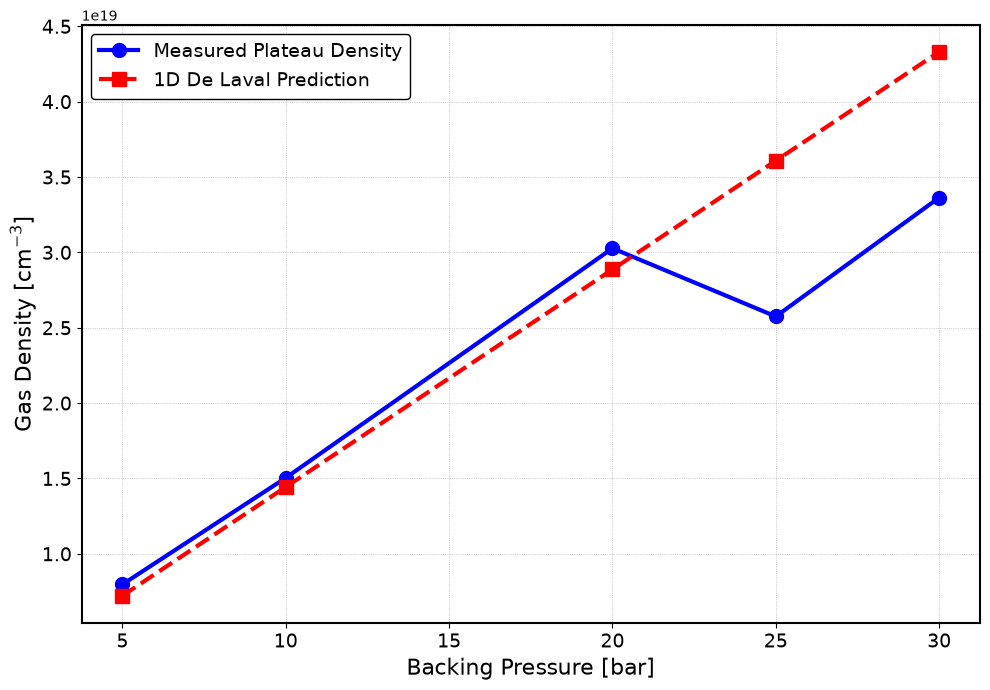

Pressure | Measured Density | Theoretical Density | Ratio (Theo/Meas)
-----------------------------------------------------------------
     5 bar |       7.97e+18 |          7.22e+18 |          0.91x
    10 bar |       1.50e+19 |          1.44e+19 |          0.96x
    20 bar |       3.03e+19 |          2.89e+19 |          0.95x
    25 bar |       2.57e+19 |          3.61e+19 |          1.40x
    30 bar |       3.36e+19 |          4.33e+19 |          1.29x


In [69]:
# %% [markdown]
# # Density vs Pressure Comparison

# %%
# Create a mask to exclude 15 bar
mask = pressures != 15
plot_pressures = pressures[mask]
plot_measured = measured_means[mask]
plot_theoretical = theoretical_densities[mask]

fig, ax = plt.subplots(figsize=(10, 7), facecolor="white")
ax.set_facecolor("white")

# Plot empirical measurements using filtered data
ax.plot(plot_pressures, plot_measured, marker='o', color="blue", linewidth=3, markersize=10,
        label="Measured Plateau Density")

# Plot theoretical predictions using filtered data
ax.plot(plot_pressures, plot_theoretical, marker='s', color="red", linestyle="--", linewidth=3, markersize=10,
        label="1D De Laval Prediction")

# ax.set_title("Mean Density at Exit vs. Backing Pressure", fontsize=20, color="black", fontweight="bold", pad=15)
ax.set_xlabel("Backing Pressure [bar]", fontsize=16, color="black")
ax.set_ylabel("Gas Density [cm$^{-3}$]", fontsize=16, color="black")
ax.tick_params(colors="black", labelsize=14)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.5)

ax.grid(True, linestyle=":", alpha=0.7, color="gray")

legend = ax.legend(loc="upper left", fontsize=14, facecolor="white", framealpha=1.0, edgecolor="black")
for text in legend.get_texts():
    text.set_color("black")

plt.tight_layout()
plt.show()

print("Pressure | Measured Density | Theoretical Density | Ratio (Theo/Meas)")
print("-" * 65)
for p, meas, theo in zip(plot_pressures, plot_measured, plot_theoretical):
    ratio = theo / meas
    print(f"{p:>6} bar | {meas:>14.2e} | {theo:>17.2e} | {ratio:>13.2f}x")

In [74]:
# %% [markdown]
# # 10 Bar Derivative Analysis

# %%
# Retrieve the 10 bar data from the pre-calculated dictionary
data_5bar = results_2d[5]
px_to_mm = data_5bar["px_to_mm"]
x_left = data_5bar["x_left"]
x_right = data_5bar["x_right"]
density_map_5bar = data_5bar["density_map"]

# Extract 1D profile right at the nozzle exit (y=0)
lineout_5bar = density_map_5bar[0, int(x_left):int(x_right)]
x_axis_mm = np.arange(len(lineout_5bar)) * px_to_mm

# 1. Find the maximum density and its spatial location
max_idx = np.argmax(lineout_5bar)
density_max = lineout_5bar[max_idx]
location_of_max_mm = x_axis_mm[max_idx]

# 2. Calculate the measured mean between 1.0mm and 3.5mm
start_px = int(1.0 / px_to_mm)
end_px = int(3.5 / px_to_mm)
measured_mean = np.mean(lineout_5bar[start_px:end_px])

# 3. Calculate the density derivative
# Formula: (density_max - measured_mean) / (location_of_max_mm - 3)
density_derivative = (density_max - measured_mean) / (location_of_max_mm - 3.0)

# 4. Calculate the final requested ratio
final_ratio = measured_mean / density_derivative

# Print results
print(f"{'='*40}")
print(f"10 Bar Derivative Analysis")
print(f"{'='*40}")
print(f"Max Density:             {density_max:.2e} cm^-3")
print(f"Location of Max (x):     {location_of_max_mm:.3f} mm")
print(f"Measured Mean (1-3.5mm): {measured_mean:.2e} cm^-3")
print(f"Density Derivative:      {density_derivative:.2e} cm^-3/mm")
print(f"Final Ratio (Max/Deriv): {final_ratio:.4f} mm")

10 Bar Derivative Analysis
Max Density:             1.76e+19 cm^-3
Location of Max (x):     4.099 mm
Measured Mean (1-3.5mm): 7.97e+18 cm^-3
Density Derivative:      8.78e+18 cm^-3/mm
Final Ratio (Max/Deriv): 0.9079 mm
